In [2]:
%reset -f

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap
from tensorflow.keras.models import load_model
import torch
import torch.nn as nn
import joblib
import json
from pathlib import Path
from datetime import datetime

import sys
sys.path.append("../../tools")
import architec as acht
import evaluation as eva
import prepare as prep
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [3]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
#importlib.reload(func)


**Entropy and Diversity**

In [ ]:
all_metrics = []

for rep in range(15):
    # Model loading
    #load_dir = Path(f"../../saved_models/sta_entropy/sp3to20_MD_transpt_R49_r{rep+1}")
    #load_dir = Path(f"../../saved_models/diversity/sp3to20_MD_transpt_R84_r{rep+1}")
    #load_dir = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r{rep+1}")
    load_dir = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r{rep+1}")
    
    # scaler
    scaler_g = joblib.load(load_dir / "scaler_g.pkl")
    scaler_d = joblib.load(load_dir / "scaler_d.pkl")

    # config
    with open(load_dir / "config.json") as f:
        config = json.load(f)

    NumSpecies = config["NumSpecies"]
    featgam = config["featgam"]
    task_num = config["task_num"]
    # n_class = config["n_class"]
    embed_dim = config["embed_dim"]
    num_heads = config["num_heads"]
    ff_dim = config["ff_dim"]

    model = acht.MDTrans2(NumSpecies).to(device)

    model.load_state_dict(torch.load(load_dir / "model.pt", map_location=device))

    split_df = pd.read_csv(f"split_MD_v1/split_MD_{rep+1}.csv")
    folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20"

    #-----different richness testset--------
    for rich in range(3, 21):
        narray_te = prep.load_split_dataset(
            split_df,
            folder_path,
            richness_list=[rich],
            #richness_list=list(range(3,21)),
            subset="te"
        )

        Xg_te, XA_te, Xd_te, y_te, idx_te = prep.prepare_test(
            narray_te,
            NumSpecies,
            featgam,
            scaler_g,
            scaler_d,
            task_num,
            #sample_size=17000,                
            random_state=42
        )

        Xg_te = torch.as_tensor(Xg_te, dtype=torch.float32, device=device)
        XA_te = torch.as_tensor(XA_te, dtype=torch.float32, device=device)
        Xd_te = torch.as_tensor(Xd_te, dtype=torch.float32, device=device)

        model.eval()
        with torch.no_grad():
            pred = model(Xg_te, XA_te, Xd_te)
            y_pred = pred.cpu().numpy().ravel()

        metrics = eva.eval_regression(y_te, y_pred)
        metrics["rep"] = rep + 1
        metrics["test_richness"] = rich
        all_metrics.append(metrics)

df_metrics = pd.DataFrame(all_metrics)
#df_metrics.to_pickle("sta_entropy2.pkl")
df_metrics.to_pickle("diversity2.pkl")


**Number of stable states**

In [ ]:
all_metrics = []

for rep in range(15):

    load_dir = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r{rep+1}")
    nmodel = func.load_saved_model_NS(load_dir, device)
    nevaluator = func.TrteEvaluator(nmodel)

    split_df = pd.read_csv(f"split_MD_v1/split_MD_{rep+1}.csv")
    folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20"

    #-----different richness testset--------
    for rich in range(3, 21):
        narray_te = prep.load_split_dataset(
            split_df,
            folder_path,
            richness_list=[rich],
            #richness_list=list(range(3,21)),
            subset="te"
        )

        # Evaluate the model on the test set
        y_te, y_prob = nevaluator.predict_array_NS(narray_te, device, sample_size=None)

        metrics = eva.eval_multiclass(nmodel["n_class"], y_te, y_prob)
        metrics["rep"] = rep + 1
        metrics["test_richness"] = rich   
        all_metrics.append(metrics)

df_metrics = pd.DataFrame(all_metrics)
df_metrics.to_pickle("num_sta2.pkl")


**Figure draw, directly call the stored file like diversity.pkl**

In [4]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border thickness
    'legend.fontsize': 7, # legend font size (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick labels (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial
    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# Load data
df_sta = pd.read_pickle("sta_entropy2.pkl")
df_div = pd.read_pickle("diversity2.pkl")
df_num = pd.read_pickle("num_sta2.pkl")


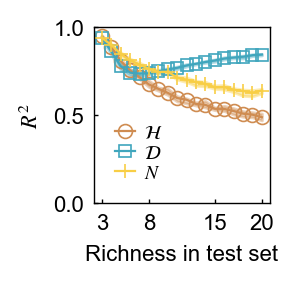

In [6]:
plot_sta = df_sta.groupby("test_richness")["R2"].agg(mean="mean", min="min", max="max").reset_index()
plot_div = df_div.groupby("test_richness")["R2"].agg(mean="mean", min="min", max="max").reset_index()
plot_num = df_num.groupby("test_richness")["R2_ord_expect"].agg(mean="mean", min="min", max="max").reset_index()

plt.figure(figsize=(1.1,1.1), dpi=200)

# Colors
color_sta = "#cf8c51"
color_div = "#40a6bd"
color_num = "#f8ce45"

# ---------- Stable-state entropy ----------
plt.plot(
    plot_sta["test_richness"],
    plot_sta["mean"],
    color=color_sta,
    marker='o',
    markersize=5,
    markerfacecolor='none',
    markeredgewidth=0.6,
    linewidth=0.8,
    label=r"$\mathcal{H}$"
)

poly = plt.fill_between(
    plot_sta["test_richness"],
    plot_sta["min"],
    plot_sta["max"],
    color=color_sta,
    alpha=0.4
)
poly.set_rasterized(True)

# ---------- Diversity ----------
plt.plot(
    plot_div["test_richness"],
    plot_div["mean"],
    color=color_div,
    marker='s',
    markersize=4,
    markerfacecolor='none',
    markeredgewidth=0.6,
    linewidth=0.8,
    label=r"$\mathcal{D}$"
)

poly = plt.fill_between(
    plot_div["test_richness"],
    plot_div["min"],
    plot_div["max"],
    color=color_div,
    alpha=0.4
)
poly.set_rasterized(True)

# ---------- Number of stable state ----------
plt.plot(
    plot_num["test_richness"],
    plot_num["mean"],
    color=color_num,
    marker='+',
    markersize=5,
    markerfacecolor='none',
    markeredgewidth=0.6,
    linewidth=0.8,
    label=r"$N$"
)

poly = plt.fill_between(
    plot_num["test_richness"],
    plot_num["min"],
    plot_num["max"],
    color=color_num,
    alpha=0.4
)
poly.set_rasterized(True)

plt.xlabel("Richness in test set")
plt.ylabel(r"$R^2$")
plt.xticks([3, 8, 15, 20])
plt.ylim(0,1)

plt.tick_params(direction='in')
plt.grid(False)

plt.legend(
    frameon=False,
    fontsize=7,
    handlelength=1.0,   # legend line length
    handletextpad=0.5,  # spacing between marker and text
    labelspacing=0.1,   # vertical spacing between legend entries
    borderaxespad=0.7   # distance between legend and axes boundary
)

plt.subplots_adjust(
    left=0.18,
    right=0.98,
    bottom=0.18,
    top=0.98
)

plt.savefig(
    f"all_Richness_R2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches="tight",
    transparent=True
)

plt.show()
